In [10]:
from multi_armed_bandit import MultiArmedBandit, NoCoinsError
import random
import numpy as np
import matplotlib.pyplot as plt

In [56]:
N_RUNS = 1000
SEED = 42

In [90]:
def explore_then_exploit(mab, coins):
    n = len(mab)
    counts = np.zeros(n)
    sums = np.zeros(n)
    chosen = []

    explore_per_machine = coins // (n + 1)
    for i in range(n):
        for _ in range(explore_per_machine):
            sums[i] += mab[i].pull()
            counts[i] += 1
            chosen.append(i)

    best = int(np.argmax(sums / counts))
    while not mab.empty():
        mab[best].pull()
        chosen.append(best)
    return chosen

In [86]:
def ucb(mab, coins):
    n = len(mab)
    counts = np.zeros(n)
    sums = np.zeros(n)
    chosen = []

    t = 0
    while not mab.empty():
        t += 1
        if (counts == 0).any():
            i = int(np.argmax(counts == 0))
        else:
            i = int(np.argmax(sums / counts + np.sqrt(2 * np.log(t) / counts)))
        sums[i] += mab[i].pull()
        counts[i] += 1
        chosen.append(i)
    return chosen

In [87]:
def thompson(mab, coins):
    n = len(mab)
    alpha = np.ones(n)
    beta = np.ones(n)
    chosen = []

    while not mab.empty():
        i = int(np.argmax(np.random.beta(alpha, beta)))
        reward = mab[i].pull()
        if reward:
            alpha[i] += 1
        else:
            beta[i] += 1
        chosen.append(i)
    return chosen

In [88]:
def play(strategy,coins):
    mab = MultiArmedBandit(coins)
    chosen = np.array(strategy(mab, coins))

    true_p = np.array(mab.rewards)
    p_star = true_p.max()

    cumulative_reward = np.cumsum(true_p[chosen])
    cumulative_regret = np.cumsum(p_star - true_p[chosen])
    return cumulative_reward, cumulative_regret, p_star

In [92]:
STRATEGIES = {
    "Explore-then-Exploit": explore_then_exploit,
    "UCB": ucb,
    "Thompson Sampling": thompson,
}

In [82]:
def run_experiment(strategy, coins):
    np.random.seed(SEED)
    random.seed(SEED)
    rewards = np.zeros((N_RUNS, coins))
    regrets = np.zeros((N_RUNS, coins))
    for run in range(N_RUNS):
        rewards[run], regrets[run], p_star = play(strategy, coins)
    return rewards, regrets, p_star

def main(coins=100):
    p_star = 0.0
    steps = np.arange(1, coins + 1)
    fig, (ax_reward, ax_regret) = plt.subplots(1, 2, figsize=(13, 5))

    final_regrets = {}
    for name, strategy in STRATEGIES.items():
      rewards, regrets, p_star = run_experiment(strategy, coins)
      total_reward = rewards[:, -1]
      total_regret = regrets[:, -1]
      final_regrets[name] = total_regret.mean()

      ax_reward.plot(steps, rewards.mean(axis=0), label=name)
      ax_regret.plot(steps, regrets.mean(axis=0), label=name)

    anchor = final_regrets.get("Thompson Sampling", max(final_regrets.values()))
    log_reference = anchor * np.log(steps) / np.log(COINS)
    ax_regret.plot(steps, log_reference, "g-.", alpha=0.7, label="log T - Thompson Sampling reference")

    anchor = final_regrets.get("UCB", max(final_regrets.values()))
    log_reference = anchor * np.log(steps) / np.log(COINS)
    ax_regret.plot(steps, log_reference, "-.", color='darkorange', alpha=0.7, label="log T - UCB1 reference")

    ax_reward.set_title("Average cumulative reward over time")
    ax_reward.set_xlabel("Step (coin)")
    ax_reward.set_ylabel("Reward")
    ax_reward.legend()
    ax_reward.grid(alpha=0.3)

    ax_regret.set_title("Average cumulative regret over time")
    ax_regret.set_xlabel("Step (coin)")
    ax_regret.set_ylabel("Regret")
    ax_regret.legend()
    ax_regret.grid(alpha=0.3)

    fig.tight_layout()
    plt.show()

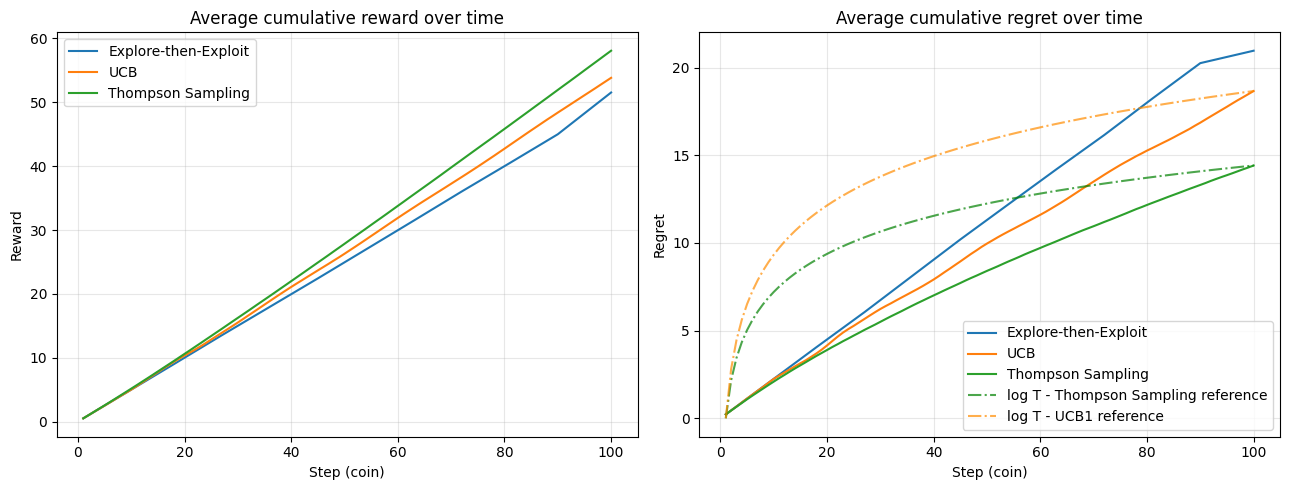

In [93]:
main(coins=100)

Let's check for 1000 coins...

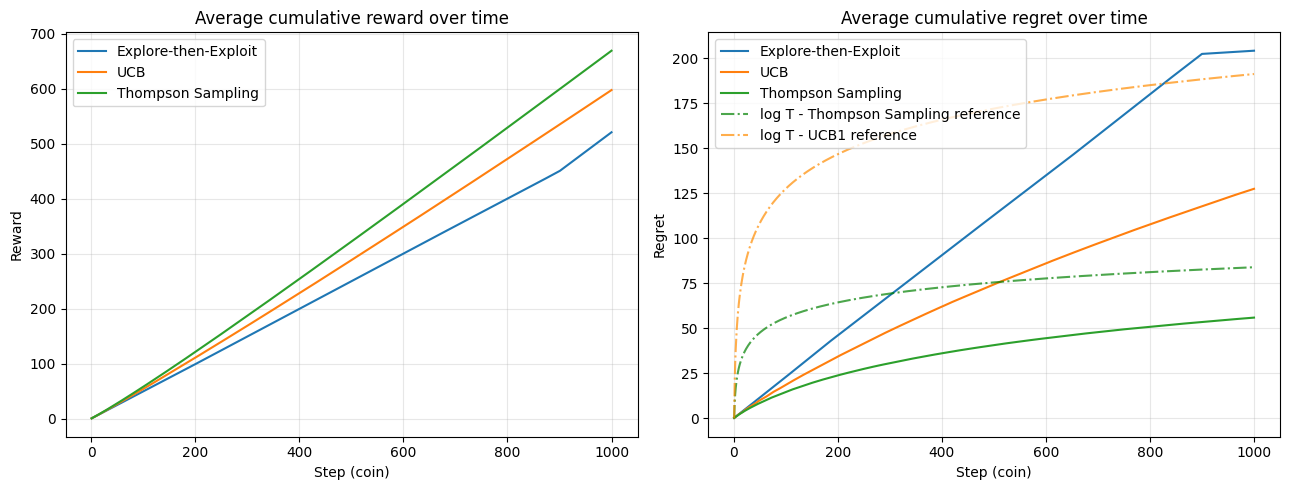

In [94]:
main(coins=1000)

Log(T) is the number of pulls. It serves as the reference for a theoretical bound of Thompson Sampling and UCB1 strategies. Both strategies seems to follow the trend in the long term but not at the begining. Bayesian sampling in Thompson yields the best total reward with the lowest total regret in most of the steps (#pulls).